# Medicare Provider Data Quality & Anomaly Analysis

**Author:** Khagendra Adhikari

This notebook explores a nonrandom 5,000-row Maryland sample from the CMS 2024 *Medicare Physician & Other Practitioners — by Provider and Service* dataset. Each original record summarizes one provider, one procedure code, and one place of service for reporting year 2024. Procedure-code columns have been excluded from this sample, so this file cannot support procedure-code-specific analysis.

I’ll start with basic structure and data-quality checks, then summarize four measures. These sampled records are not a random sample of all CMS records, so results describe this file rather than all Medicare providers or services.

In [1]:
from pathlib import Path
import pandas as pd

# Support launching Jupyter from either the project root or notebook/ folder.
possible_paths = [Path.cwd() / 'data' / 'cms_md_2024_sample.csv',
                  Path.cwd().parent / 'data' / 'cms_md_2024_sample.csv']
csv_path = next((path for path in possible_paths if path.exists()), None)
if csv_path is None:
    raise FileNotFoundError('Could not find data/cms_md_2024_sample.csv from the current directory.')

df = pd.read_csv(csv_path, dtype={'Rndrng_NPI': 'string'})
print(f'Loaded {df.shape[0]:,} rows and {df.shape[1]:,} columns.')

Loaded 5,000 rows and 12 columns.


## Structure and completeness

I report schema and counts only; I avoid displaying identifiers or individual provider records. Missing values mean a value is unreported or unavailable. A zero is a recorded numeric value and is not the same as missing. CMS privacy suppression can remove service records with low beneficiary counts, so absence of a record does not mean the service was never provided.

In [2]:
print('Column names:', list(df.columns))
print('Data types:\n', df.dtypes.to_string())
print('Missing values by column:\n', df.isna().sum().to_string())
print(f'Distinct nonmissing NPIs: {df["Rndrng_NPI"].nunique(dropna=True):,}')
code_columns = [name for name in df.columns if 'CPT' in name.upper() or 'HCPCS' in name.upper()]
print('CPT/HCPCS columns loaded:', code_columns)

Column names: ['Rndrng_NPI', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_Type', 'Place_Of_Srvc', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs', 'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt', 'sample_offset_block']
Data types:
 Rndrng_NPI                   string[python]
Rndrng_Prvdr_State_Abrvtn            object
Rndrng_Prvdr_Type                    object
Place_Of_Srvc                        object
Tot_Benes                             int64
Tot_Srvcs                           float64
Tot_Bene_Day_Srvcs                    int64
Avg_Sbmtd_Chrg                      float64
Avg_Mdcr_Alowd_Amt                  float64
Avg_Mdcr_Pymt_Amt                   float64
Avg_Mdcr_Stdzd_Amt                  float64
sample_offset_block                   int64
Missing values by column:
 Rndrng_NPI                   0
Rndrng_Prvdr_State_Abrvtn    0
Rndrng_Prvdr_Type            0
Place_Of_Srvc                0
Tot_Benes                    0
Tot_Srvcs                  

## Numeric measures

I explicitly coerce the seven known numeric measures. A conversion failure is a nonmissing original value that becomes missing after conversion; I count and report those cases instead of dropping any rows. The original record totals and beneficiary counts describe service records. In particular, I do not add average payment amounts or `Tot_Benes` across service records, because those sums would not be meaningful provider or population totals.

In [3]:
numeric_columns = ['Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs',
                   'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt',
                   'Avg_Mdcr_Pymt_Amt', 'Avg_Mdcr_Stdzd_Amt']
conversion_failures = {}
for column in numeric_columns:
    original = df[column]
    converted = pd.to_numeric(original, errors='coerce')
    conversion_failures[column] = int((original.notna() & converted.isna()).sum())
    df[column] = converted
print('Conversion failures by measure:', conversion_failures)
print(f'Rows retained: {len(df):,}')

Conversion failures by measure: {'Tot_Benes': 0, 'Tot_Srvcs': 0, 'Tot_Bene_Day_Srvcs': 0, 'Avg_Sbmtd_Chrg': 0, 'Avg_Mdcr_Alowd_Amt': 0, 'Avg_Mdcr_Pymt_Amt': 0, 'Avg_Mdcr_Stdzd_Amt': 0}
Rows retained: 5,000


## Descriptive statistics

These summaries describe the distribution of the selected service-record measures. Counts reflect available numeric values; missing values remain missing and are not replaced with zero.

In [4]:
summary_columns = ['Tot_Srvcs', 'Avg_Sbmtd_Chrg',
                   'Avg_Mdcr_Alowd_Amt', 'Avg_Mdcr_Pymt_Amt']
percentiles = [0.25, 0.50, 0.75, 0.90]
summary = df[summary_columns].describe(percentiles=percentiles).T
summary = summary.rename(columns={'25%': '25th percentile', '50%': 'median',
                                  '75%': '75th percentile', '90%': '90th percentile'})
summary = summary[['count', 'mean', 'median', 'min', 'max', 'std',
                   '25th percentile', '75th percentile', '90th percentile']]
summary

,count,mean,median,min,max,std,25th percentile,75th percentile,90th percentile
Tot_Srvcs,5000.0,266.160460,49.000000,11.000000,64044.000000,1826.123138,22.000000,135.250000,409.000000
Avg_Sbmtd_Chrg,5000.0,388.611643,178.000000,0.200000,46685.000000,1037.365999,71.458214,355.000000,801.968076
Avg_Mdcr_Alowd_Amt,5000.0,112.055636,77.098323,0.050000,10144.937895,273.108977,29.201705,130.561824,187.395043
Avg_Mdcr_Pymt_Amt,5000.0,87.824123,57.445463,0.037222,8082.958947,217.672268,22.332898,97.429204,150.470143


## Data quality checks

I check completeness, possible duplicate rows, negative values in the requested measures, state consistency, and numeric data types. Because HCPCS fields were excluded, matching rows in this reduced file are projected duplicates, not confirmed duplicates in the complete source data. Fractional `Tot_Srvcs` values are not automatically invalid, so I do not flag or change them. These checks report aggregates only and do not repair or remove data.

In [5]:
print('Missing values by column:')
print(df.isna().sum().to_string())
print(f'Projected duplicate rows: {int(df.duplicated().sum()):,}')

checked_measures = ['Tot_Benes', 'Tot_Srvcs', 'Tot_Bene_Day_Srvcs',
                    'Avg_Sbmtd_Chrg', 'Avg_Mdcr_Alowd_Amt',
                    'Avg_Mdcr_Pymt_Amt']
negative_counts = df[checked_measures].lt(0).sum()
print('Negative values by measure:')
print(negative_counts.to_string())

state_check = df['Rndrng_Prvdr_State_Abrvtn'].eq('MD')
print(f'All provider states are MD: {bool(state_check.all())}')
print(f'Rows with a non-MD state: {int((~state_check).sum()):,}')

expected_numeric = numeric_columns
numeric_type_check = df[expected_numeric].dtypes.apply(pd.api.types.is_numeric_dtype)
print('Numeric type check by column:')
print(numeric_type_check.to_string())
print(f'All expected measures are numeric: {bool(numeric_type_check.all())}')

Missing values by column:
Rndrng_NPI                   0
Rndrng_Prvdr_State_Abrvtn    0
Rndrng_Prvdr_Type            0
Place_Of_Srvc                0
Tot_Benes                    0
Tot_Srvcs                    0
Tot_Bene_Day_Srvcs           0
Avg_Sbmtd_Chrg               0
Avg_Mdcr_Alowd_Amt           0
Avg_Mdcr_Pymt_Amt            0
Avg_Mdcr_Stdzd_Amt           0
sample_offset_block          0
Projected duplicate rows: 3
Negative values by measure:
Tot_Benes             0
Tot_Srvcs             0
Tot_Bene_Day_Srvcs    0
Avg_Sbmtd_Chrg        0
Avg_Mdcr_Alowd_Amt    0
Avg_Mdcr_Pymt_Amt     0
All provider states are MD: True
Rows with a non-MD state: 0
Numeric type check by column:
Tot_Benes             True
Tot_Srvcs             True
Tot_Bene_Day_Srvcs    True
Avg_Sbmtd_Chrg        True
Avg_Mdcr_Alowd_Amt    True
Avg_Mdcr_Pymt_Amt     True
Avg_Mdcr_Stdzd_Amt    True
All expected measures are numeric: True


## Distributions

Both measures are right-skewed. I use log-spaced histogram bins and a logarithmic x-axis so the full positive-value range remains visible; no observations are removed. The horizontal axes show services per service record and dollars per service record, respectively.

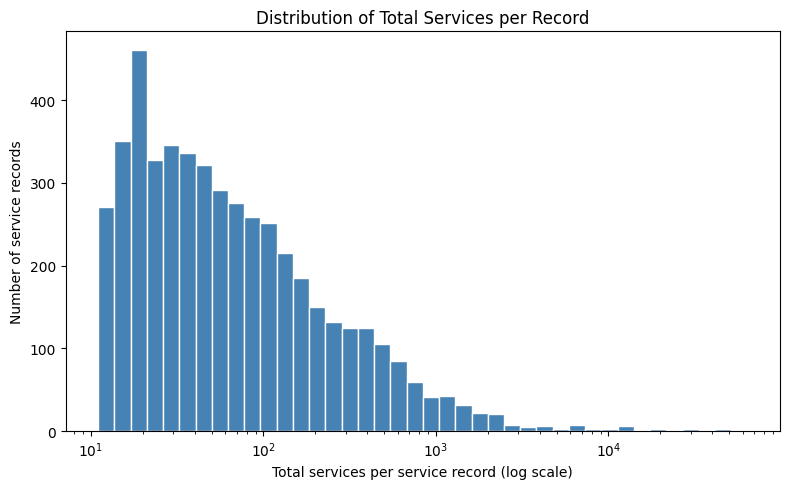

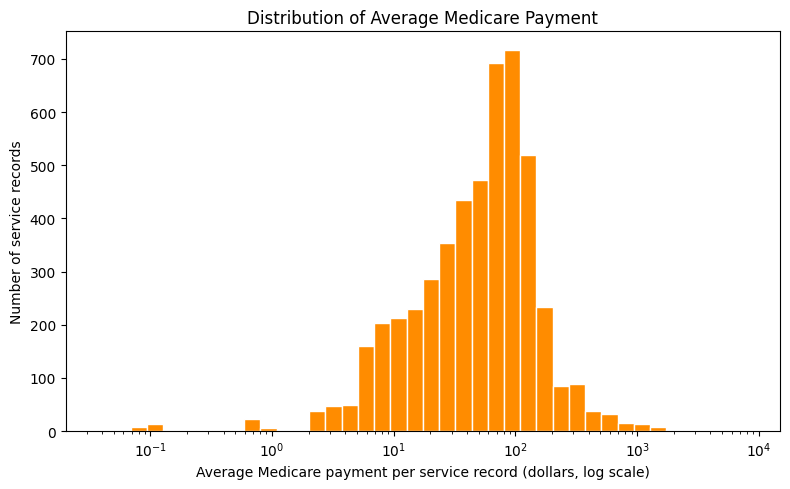

Saved figures: True True


In [6]:
import matplotlib.pyplot as plt
import numpy as np

figure_dir = csv_path.parent.parent / 'figures'
figure_dir.mkdir(exist_ok=True)

service_values = df['Tot_Srvcs'].dropna()
service_bins = np.logspace(np.log10(service_values.min()), np.log10(service_values.max()), 41)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(service_values, bins=service_bins, color='steelblue', edgecolor='white')
ax.set_xscale('log')
ax.set_title('Distribution of Total Services per Record')
ax.set_xlabel('Total services per service record (log scale)')
ax.set_ylabel('Number of service records')
fig.tight_layout()
fig.savefig(figure_dir / 'service_volume.png', dpi=150)
plt.show()
plt.close(fig)

payment_values = df['Avg_Mdcr_Pymt_Amt'].dropna()
payment_bins = np.logspace(np.log10(payment_values.min()), np.log10(payment_values.max()), 41)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(payment_values, bins=payment_bins, color='darkorange', edgecolor='white')
ax.set_xscale('log')
ax.set_title('Distribution of Average Medicare Payment')
ax.set_xlabel('Average Medicare payment per service record (dollars, log scale)')
ax.set_ylabel('Number of service records')
fig.tight_layout()
fig.savefig(figure_dir / 'payment_distribution.png', dpi=150)
plt.show()
plt.close(fig)
print('Saved figures:', (figure_dir / 'service_volume.png').exists(),
      (figure_dir / 'payment_distribution.png').exists())

## IQR-Based Outlier Screening

For `Avg_Mdcr_Pymt_Amt`, Q1 is the 25th percentile and Q3 is the 75th percentile. The interquartile range (IQR) is Q3 − Q1. The standard lower and upper fences are Q1 − 1.5 × IQR and Q3 + 1.5 × IQR; values strictly outside these fences are flagged. Missing and infinite values are excluded from quartile calculation and flagging. If IQR is zero, the same fence rule still applies without dividing by IQR.

I use this as a global, unadjusted comparison across mixed medical services, not as a provider-level anomaly assessment. A statistical outlier alone does not establish fraud, waste, abuse, or noncompliance. Flagged observations remain in the data.

Finite, nonmissing payment values: 5,000
Q1: $22.33
Q3: $97.43
IQR: $75.10
Lower fence: $-90.31
Upper fence: $210.07
Low outliers: 0
High outliers: 279
Total outliers: 279
Percentage of sampled rows flagged: 5.58%
IQR is zero: False
Figure already exists; leaving it unchanged: C:\Users\sabin\Khagen\GitHub\medicare-provider-data-quality-minimal\figures\payment_iqr.png


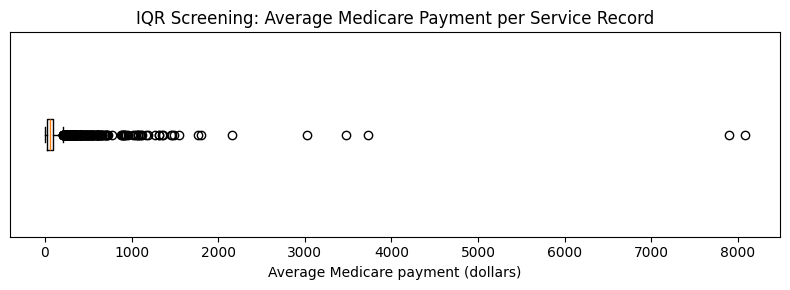

Saved boxplot: True


In [7]:
payment = df['Avg_Mdcr_Pymt_Amt']
finite_payment = payment[payment.notna() & np.isfinite(payment)]
if finite_payment.empty:
    raise ValueError('No finite, nonmissing payment values are available for IQR screening.')

q1 = finite_payment.quantile(0.25)
q3 = finite_payment.quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
low_outliers = finite_payment < lower_fence
high_outliers = finite_payment > upper_fence
outlier_count = int(low_outliers.sum() + high_outliers.sum())
flagged_percent = outlier_count / len(df) * 100 if len(df) else 0.0

print(f'Finite, nonmissing payment values: {len(finite_payment):,}')
print(f'Q1: ${q1:,.2f}')
print(f'Q3: ${q3:,.2f}')
print(f'IQR: ${iqr:,.2f}')
print(f'Lower fence: ${lower_fence:,.2f}')
print(f'Upper fence: ${upper_fence:,.2f}')
print(f'Low outliers: {int(low_outliers.sum()):,}')
print(f'High outliers: {int(high_outliers.sum()):,}')
print(f'Total outliers: {outlier_count:,}')
print(f'Percentage of sampled rows flagged: {flagged_percent:.2f}%')
print(f'IQR is zero: {bool(iqr == 0)}')

iqr_figure_path = csv_path.parent.parent / 'figures' / 'payment_iqr.png'
save_iqr_figure = not iqr_figure_path.exists()
if not save_iqr_figure:
    print(f'Figure already exists; leaving it unchanged: {iqr_figure_path}')
fig, ax = plt.subplots(figsize=(8, 3))
ax.boxplot(finite_payment, vert=False, showfliers=True)
ax.set_title('IQR Screening: Average Medicare Payment per Service Record')
ax.set_xlabel('Average Medicare payment (dollars)')
ax.set_yticks([])
fig.tight_layout()
if save_iqr_figure:
    fig.savefig(iqr_figure_path, dpi=150)
plt.show()
plt.close(fig)
print(f'Saved boxplot: {iqr_figure_path.exists()}')

## Findings and Limitations

This sample contains 5,000 rows and 567 distinct NPIs. It has no missing values or negative values in the checked measures, and three projected duplicate rows. Median `Tot_Srvcs` is 49; median `Avg_Mdcr_Pymt_Amt` is $57.45. The payment IQR fences are −$90.31 and $210.07; 279 high and zero low values are flagged (5.58% of sampled rows).

I use a nonrandom Maryland sample with incomplete provider coverage. Service types are mixed, HCPCS/CPT fields are absent, and CMS privacy suppression can affect which records appear. The global, unadjusted IQR screen is not a provider investigation or evidence of fraud, waste, abuse, or noncompliance. The aggregate file does not support patient-level clinical risk adjustment.